## Visualization of CDK4/6i simulations

Based on code in Fig5.ipynb and Lyap-Dist_comp.ipynb

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
from pathlib import Path
import re
import sys
import joblib
import pandas as pd

from random import randint

sys.path.insert(0, "../../Python/cellular_cycle")
from model_fxns import get_traj, plot_traj, restructProt, cosine_similarity, get_cos_similarities

from scipy.ndimage import gaussian_filter
from scipy.signal import find_peaks
from statistics import mean


### Set global variables

In [2]:
SAVEFILES = True
OVERWRITE = False

SAVE_DIR = Path("~/ECM_mod_output/").expanduser()

rcParams.update({'figure.autolayout': True})

sys_type = sys.platform
# stoch_embed_fn = Path('../../Data/UMAP_embeddings/all_embedding_stoch_cdk46i.sav')
stoch_embed_fn = Path('../../Data/UMAP_embeddings/all_embedding_stoch_cdk46i_allconds_win.sav')
ode_embed_fn = Path(str(stoch_embed_fn).replace('stoch', 'ode'))

if sys_type == 'darwin':
    sys_name = 'mac'
elif sys_type == 'win32': 
    sys_name = 'win'
elif sys_type == 'linux': 
    sys_name = 'linux'


### Load UMAP embedding of CDK4/6i data
UMAP embeddings should be `SAVE_DIR`. If they are not detected, they will be downloaded automatically.  

Order of samples in data:  
1) soft DMSO
1) int DMSO 
1) stiff DMSO
1) soft ERL
1) int ERL
1) stiff ERL
1) soft CDK4/6i
1) int CDK4/6i 
1) stiff CDK4/6i
1) soft ERL + CDK4/6i
1) int ERL + CDK4/6i 
1) stiff ERL + CDK4/6i


In [3]:
embed_dat = joblib.load(stoch_embed_fn)
stoch_l = int(len(embed_dat)/12)
stoch_l

39993

In [4]:
embed_dat_ode = joblib.load(ode_embed_fn)
ode_l = int(len(embed_dat_ode)/12)
ode_l

10000

In [5]:
def get_traj(embed_dat, pos, trk_len):
    if pos > len(embed_dat)/trk_len:
        print('Position out of range')
        return np.nan   
    embed_traj = embed_dat[pos*trk_len:(pos+1)*trk_len]
    return embed_traj

In [6]:
col = ['blue','blue','blue','red','red','red','orange','orange','orange','black','black','black',]
plot_ode_len = [53, 50, 45, 150, 70, 60, 140, 110, 100, 900, 500, 2000,]
ode_lsty = ['dotted', 'dashed', 'solid', 'dotted', 'dashed', 'solid', 'dotted', 'dashed', 'solid','dotted', 'dashed', 'solid',]
cond = ['soft DMSO', 'int DMSO',' stiff DMSO',
        'soft ERL', 'int ERL', 'stiff ERL', 
        'soft CDK4/6i', 'int CDK4/6i', 'stiff CDK4/6i', 
        'soft CDK4/6i + ERL', 'int CDK4/6i + ERL', 'stiff CDK4/6i + ERL']


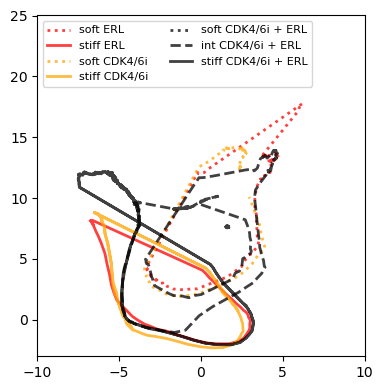

In [7]:
plt.figure(figsize=(4,4))
for i in [3,5,6,8,9,10,11,]:
    plt.plot(embed_dat_ode[i*ode_l:(i*ode_l+plot_ode_len[i]),0], 
            embed_dat_ode[i*ode_l:(i*ode_l+plot_ode_len[i]),1], 
            color=col[i], lw=2, linestyle=ode_lsty[i], alpha=.75,
            label = cond[i])

    plt.xlim(-10,10)
    plt.ylim(-3,25)

plt.legend(ncol=2, fontsize=8, loc='upper left')

    # plt.legend([cond[x] for x in [3,5,6,8,9]], loc='upper left', fontsize=8, ncol=2)


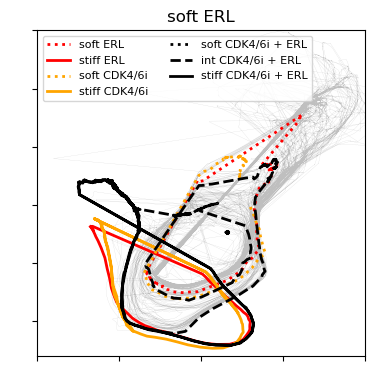

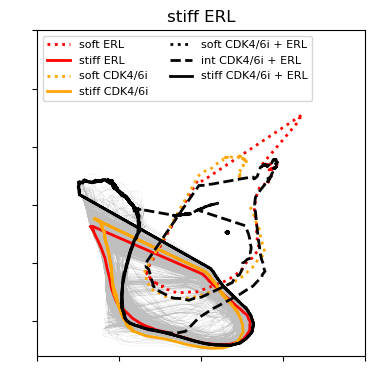

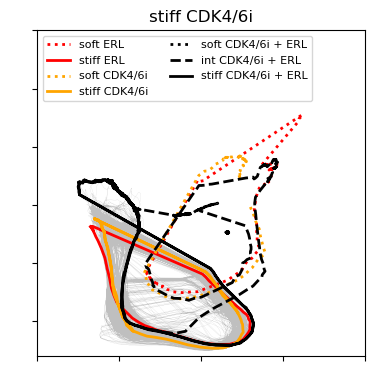

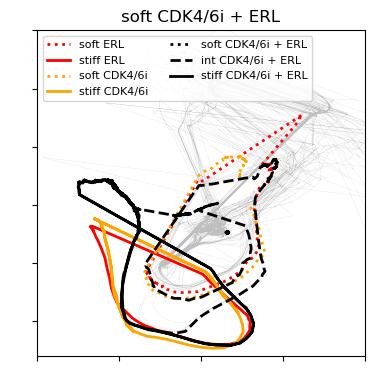

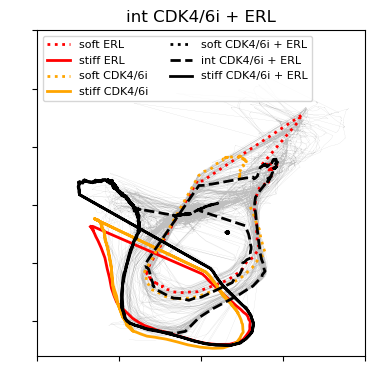

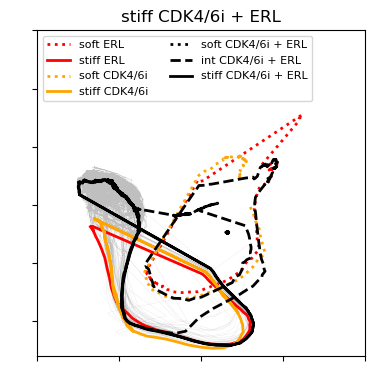

In [12]:
for pos in [3,5,8,9,10,11,]:
    plt.figure(figsize=(4,4))
    embed_plot = get_traj(embed_dat, pos, stoch_l) 
    plt.plot(embed_plot[:,0], embed_plot[:,1], lw=0.1, color='gray', alpha=0.5, label="_no_legend_")
    for i in [3,5,6,8,9,10,11,]:
        label = cond[i]
        plt.plot(embed_dat_ode[i*ode_l:(i*ode_l+plot_ode_len[i]),0], 
                embed_dat_ode[i*ode_l:(i*ode_l+plot_ode_len[i]),1], 
                color=col[i], lw=2, linestyle=ode_lsty[i], alpha=1, label=label)

        plt.xlim(-10,10)
        plt.ylim(-3,25)

        # plt.legend([cond[x] for x in [3,5,6,8,9,10,11]], loc='upper left', fontsize=8, ncol=2)
    plt.legend(loc='upper left', fontsize=8, ncol=2)

    plt.title(cond[pos])
    plt.xticks(color='w')
    plt.yticks(color='w')


In [31]:
prot_stoch_db = 'https://www.dropbox.com/scl/fi/iprgj8hoam2xsx9dmea38/all_prot_stoch_cdk46i_allconds_mac.sav?rlkey=wagqlu4x3isj5vedsvym7ylti&dl=1'
prot_stoch_fp = Path(SAVE_DIR, f'all_prot_stoch_cdk46i.sav')
time_stoch_db = 'https://www.dropbox.com/scl/fi/dh41n8v5v26av8nq9qmpg/all_time_cdk46i_tmp.sav?rlkey=ivh9armqozawg2bg5hzxxnm3l&dl=1'
time_stoch_fp = Path(SAVE_DIR, f'all_time_cdk46i_tmp.sav')

if not prot_stoch_fp.exists():
    if not sys_type == 'win32':
        os.system(f'wget -O {SAVE_DIR}/all_prot_stoch_cdk46i.sav {prot_stoch_db}')
    else:
        !curl -L -o all_prot_stoch_cdk46i.sav $prot_stoch_db
        !mv all_prot_stoch_cdk46i.sav $SAVE_DIR

all_prot = joblib.load(prot_stoch_fp)
all_prot.shape


(479916, 720)

In [32]:
type(all_prot)

numpy.ndarray

In [33]:
if not time_stoch_fp.exists():
    if not sys_type == 'win32':
        os.system(f'wget -O {time_stoch_fp} {time_stoch_db}')
    else:
        !curl -L -o all_time_cdk46i_tmp.sav $time_stoch_db
        !mv all_time_cdk46i_tmp.sav $SAVE_DIR

all_time_tmp = joblib.load(time_stoch_fp)
all_time_tmp.shape

(479916, 40)

In [34]:
embed_dat.shape

(479916, 2)

In [35]:
def dat_by_index(dat: np.ndarray, index) -> pd.DataFrame:
    return pd.DataFrame(dat[index*stoch_l:(index+1)*stoch_l])

def get_data_for_restructure(all_prot, embed_dat, all_time_tmp, index):
    return dat_by_index(all_prot, index), dat_by_index(embed_dat, index), dat_by_index(all_time_tmp, index)




In [36]:
erl_099_prot_df = dat_by_index(all_prot, 5)
erl_099_emb_df = dat_by_index(embed_dat, 5)
erl_099_time_df = dat_by_index(all_time_tmp, 5)


In [37]:
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

### Relative dwell time


In [38]:
# plot parameters
size = (5,5)
l = stoch_l # length of stochastic trajectories
lw=2

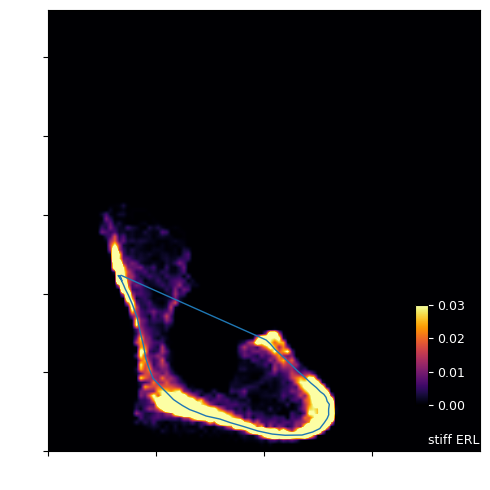

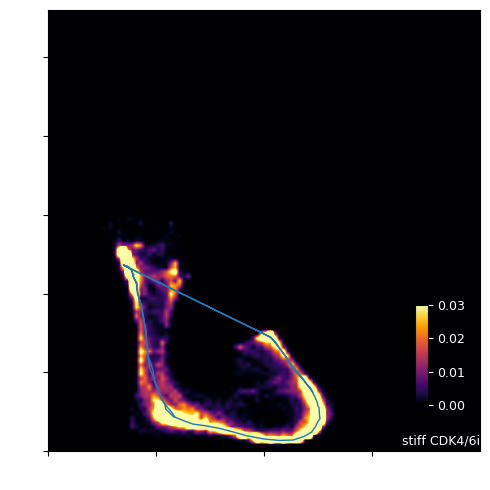

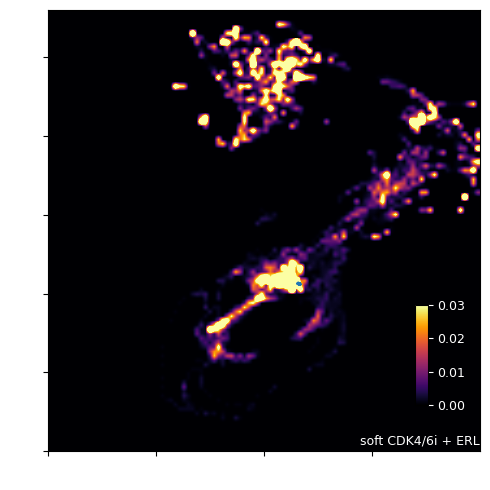

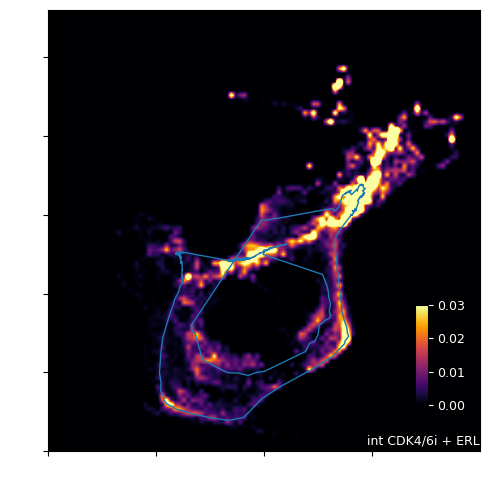

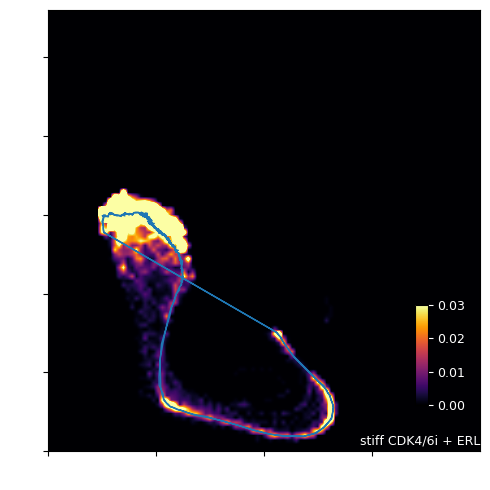

In [46]:
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

for i in [5,8,9,10,11,]:

    prot_df = dat_by_index(all_prot, i)
    emb_df = dat_by_index(embed_dat, i)
    time_df = dat_by_index(all_time_tmp, i)

    _, _, umap_win = restructProt(prot_df, emb_df, time_df)

    condition = cond[i]
    cond_name = condition.replace(' ', '_')
    cond_name = cond_name.replace('/', '')
    
    fig = plt.figure(figsize=size)
    xmin, xmax = -10, 10
    ymin, ymax = -3, 25

    x = np.array(umap_win[0])
    y = np.array(umap_win[1])
    H, xedges, yedges = np.histogram2d(x, y, bins=100, range= [[xmin,xmax], [ymin,ymax]], density=True)
    # Apply gaussian filter
    sigma = [3, 3]
    H2 = gaussian_filter(H, sigma, mode='constant')

    ax = fig.gca()

    # tmp = embed_dat_ode[i*ode_l:(i*ode_l+plot_ode_len[i]),:]
    tmp = dat_by_index(embed_dat_ode, i)
       
    im = plt.imshow((np.rot90(H)), extent=[xmin, xmax, ymin, ymax], 
                    interpolation='bilinear', cmap='inferno', aspect='auto')
    im.set_clim(0, 0.03)

    plt.plot(embed_dat_ode[i*ode_l:(i*ode_l+plot_ode_len[i]),0],
             embed_dat_ode[i*ode_l:(i*ode_l+plot_ode_len[i]),1], 
             lw=1, alpha=1)

    plt.xlim(-10,10)
    plt.ylim(-3,25)
    plt.xticks(np.arange(-10, 10, step=5))
    plt.yticks(np.arange(-3, 25, step=5))

    plt.xticks(color='w')
    plt.yticks(color='w')

    cbar_ax = fig.add_axes([0.84, 0.18, 0.025, 0.2])
    cb = fig.colorbar(im, cax=cbar_ax)
    cb.ax.tick_params(labelsize=9)
    cb.ax.yaxis.set_tick_params(color='white')
    plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')
    ax.set_title(condition, y=0, pad=5, loc='right', fontsize=9, color='white')

    filepath = Path(SAVE_DIR,f'{cond_name}_CDK46i_UMAP_heatmap.png')
    if SAVEFILES and (not filepath.exists() or OVERWRITE):
        plt.savefig(filepath, format='png', dpi=300)

### Directionality (cosine of adjacent vectors)

In [40]:
offset=1
v_len=1

stiff ERL
stiff CDK4/6i
soft CDK4/6i + ERL
int CDK4/6i + ERL
stiff CDK4/6i + ERL


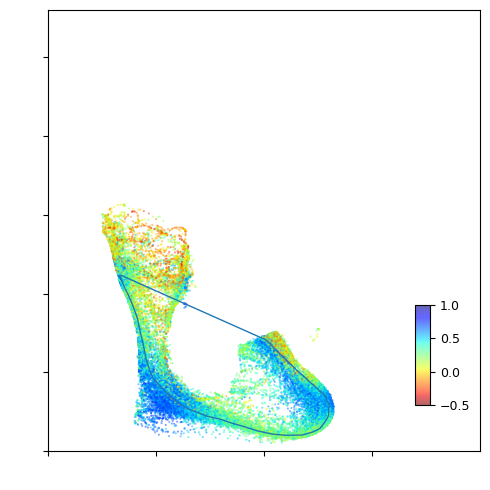

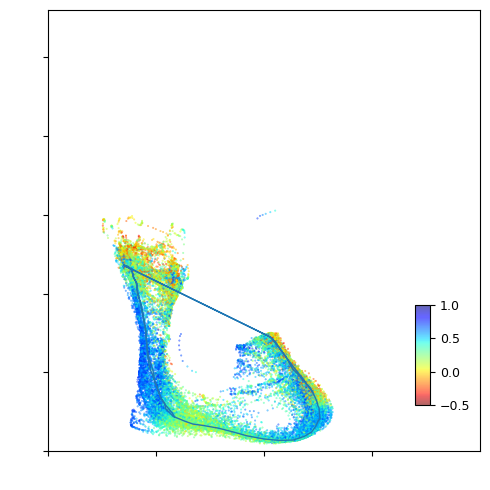

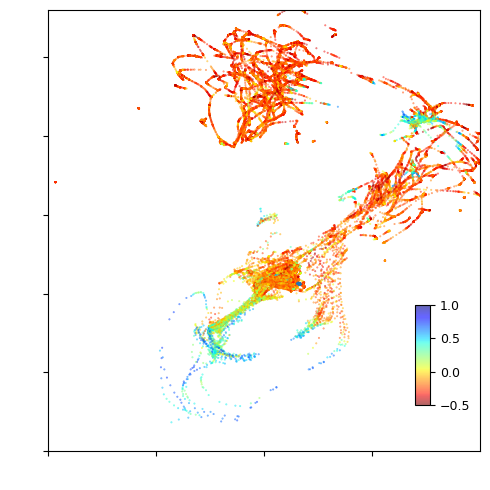

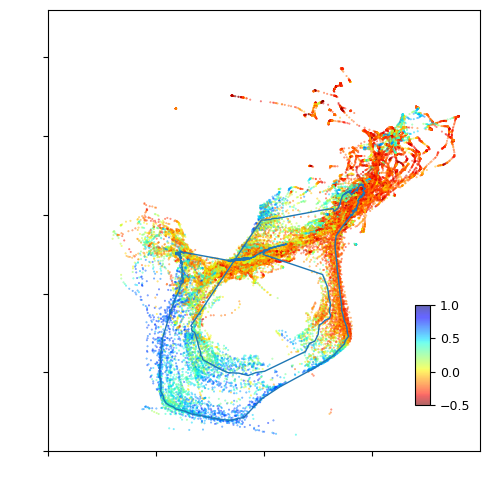

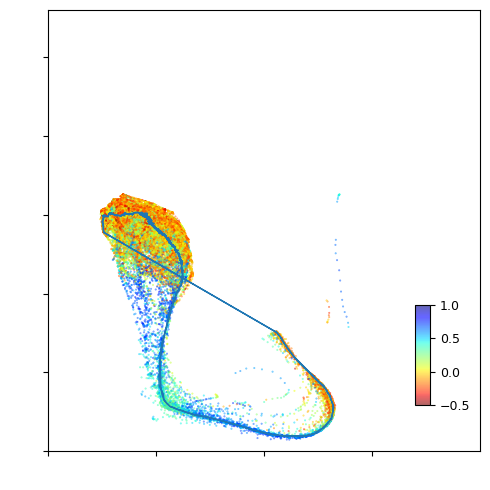

In [47]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

for i in [5,8,9,10,11,]:
    condition = cond[i]
    print(condition)
    cond_name = condition.replace(' ', '_')
    cond_name = cond_name.replace('/', '')

    cos_vals = get_cos_similarities(get_traj(all_prot, i, l), v_len, offset)
    fig = plt.figure(figsize=size)
    dat = get_traj(embed_dat, i, l-2)
    scatter1 = plt.scatter(dat[:,0], dat[:,1], s=0.2, alpha=0.6, vmin=-0.5, vmax=1, c=cos_vals, cmap='jet_r')

    plt.plot(embed_dat_ode[i*ode_l:(i*ode_l+plot_ode_len[i]),0],
             embed_dat_ode[i*ode_l:(i*ode_l+plot_ode_len[i]),1],
             lw=1, alpha=1)
    
    plt.xlim(-10,10)
    plt.ylim(-3,25)
    plt.xticks(np.arange(-10, 10, step=5))
    plt.yticks(np.arange(-3, 25, step=5))

    ax.set_title(f'{condition}', y=0, pad=5, loc='right', fontsize=9, color='black')
    plt.xticks(color='w')
    plt.yticks(color='w')

    cbar_ax = fig.add_axes([0.84, 0.18, 0.03, 0.2])
    cb = fig.colorbar(scatter1, cax=cbar_ax)
    cb.ax.tick_params(labelsize=9)

    filepath = Path(SAVE_DIR,f'{cond_name}_CDK46i_directionality.png')
    if SAVEFILES and (not filepath.exists() or OVERWRITE):
        plt.savefig(filepath, format='png', dpi=300)